In [16]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
 
import torch
from torchvision import models
import torchvision.transforms.v2 as tfs_v2
import torch.nn as nn
import torch.optim as optim

In [17]:
img = Image.open('img.jpg').convert('RGB')
img_style = Image.open('img_style.jpg').convert('RGB')

In [18]:
transforms = tfs_v2.Compose([tfs_v2.ToImage(),
                             tfs_v2.ToDtype(torch.float32, scale=True),
                             ])

img = transforms(img).unsqueeze(0)
img_style = transforms(img_style).unsqueeze(0)

# новое стилизуемое изображение
img_create = img.clone()
img_create.requires_grad_(True)

tensor([[[[0.1137, 0.1020, 0.0902,  ..., 0.0000, 0.0000, 0.0000],
          [0.1137, 0.1020, 0.0863,  ..., 0.0000, 0.0000, 0.0000],
          [0.1020, 0.1020, 0.0941,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.1490, 0.1490, 0.1490],
          [0.0000, 0.0000, 0.0000,  ..., 0.1765, 0.1765, 0.1765],
          [0.0000, 0.0000, 0.0000,  ..., 0.1961, 0.1961, 0.1961]],

         [[0.0000, 0.0000, 0.0000,  ..., 0.0078, 0.0078, 0.0078],
          [0.0000, 0.0000, 0.0000,  ..., 0.0078, 0.0078, 0.0078],
          [0.0000, 0.0000, 0.0039,  ..., 0.0078, 0.0078, 0.0078],
          ...,
          [0.0118, 0.0118, 0.0078,  ..., 0.1765, 0.1765, 0.1765],
          [0.0118, 0.0118, 0.0078,  ..., 0.2039, 0.2039, 0.2039],
          [0.0118, 0.0118, 0.0078,  ..., 0.2235, 0.2235, 0.2235]],

         [[0.0549, 0.0471, 0.0314,  ..., 0.0000, 0.0039, 0.0039],
          [0.0510, 0.0471, 0.0353,  ..., 0.0000, 0.0039, 0.0039],
          [0.0431, 0.0353, 0.0275,  ..., 0

In [19]:
model = models.vgg19(weights=models.VGG19_Weights.DEFAULT)
mf = model.features

# но так мы получим  лишь выход с последнего слоя, а нам нужны выходы с нескольких промежуточных слоёв

class ModelStyle(nn.Module):
    def __init__(self):
        super().__init__()
        _model = models.vgg19(weights=models.VGG19_Weights.DEFAULT)
        self.mf = _model.features
        self.mf.requires_grad_(False) # отключаем градиенты. так как нам не нужно ничего обучать
        # self.requires_grad_(False)
        self.mf.eval()
        self.idx_out = (0, 5, 10, 19, 28, 34) # индексы сверточных слоёв
        self.num_style_layers = len(self.idx_out) - 1 # последний слой для контента

    def forward(self, x):
        outputs = []
        for indx, layer in enumerate(self.mf):
            x = layer(x)
            if indx in self.idx_out:
                outputs.append(x.squeeze(0))

        return outputs

In [20]:
model = ModelStyle()
outputs_img = model(img)
outputs_img_style = model(img_style)

In [21]:
outputs_img

[tensor([[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],
 
         [[0.2657, 0.3930, 0.3874,  ..., 0.3138, 0.3102, 0.3165],
          [0.1669, 0.3341, 0.3436,  ..., 0.3107, 0.3058, 0.3160],
          [0.1659, 0.3206, 0.3357,  ..., 0.3107, 0.3058, 0.3160],
          ...,
          [0.2902, 0.3031, 0.3113,  ..., 0.3962, 0.3959, 0.7312],
          [0.2906, 0.3114, 0.3119,  ..., 0.3737, 0.3719, 0.7806],
          [0.2853, 0.2985, 0.3018,  ..., 0.0000, 0.0000, 0.3486]],
 
         [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ...,

Считаем потери по контенту и по стилю

In [22]:
def get_content_loss(base_content, target):
    '''потери по контенту'''
    return torch.mean( torch.square(base_content - target) )

In [23]:
def gram_matrix(x):
  channels = x.size(dim=0)
  g = x.view(channels, -1)
  gram = torch.mm(g, g.mT) / g.size(dim=1)
  return gram

In [24]:
def get_style_loss(base_style, gram_target):
    style_weights = [1.0, 0.8, 0.5, 0.3, 0.1]

    _loss = 0
    i = 0
    for base, target in zip(base_style, gram_target):
        gram_style = gram_matrix(base)
        _loss += style_weights[i] * torch.mean(torch.square(gram_style - target))
        i += 1

    return _loss

In [25]:
gram_matrix_style = [gram_matrix(x) for x in outputs_img_style[:model.num_style_layers]]
content_weight = 1
style_weight = 1000
best_loss = -1
epochs = 100

In [26]:
outputs_img_style

[tensor([[[0.0000, 0.0629, 0.0632,  ..., 0.0256, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],
 
         [[0.0000, 0.8806, 1.0826,  ..., 0.9092, 0.9551, 1.7012],
          [0.0000, 0.0318, 0.2656,  ..., 0.0838, 0.2484, 1.7087],
          [0.0000, 0.2705, 0.3495,  ..., 0.2611, 0.3757, 1.8930],
          ...,
          [0.0000, 0.2341, 0.2396,  ..., 0.3113, 0.3683, 1.6973],
          [0.0000, 0.4984, 0.2929,  ..., 0.3778, 0.3648, 1.7369],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.4197]],
 
         [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ...,

Iteration: 0, loss:  673.4964
Iteration: 1, loss:  476.3287
Iteration: 2, loss:  374.6288
Iteration: 3, loss:  292.7168
Iteration: 4, loss:  230.0598
Iteration: 5, loss:  185.2024
Iteration: 6, loss:  149.6054
Iteration: 7, loss:  124.3214
Iteration: 8, loss:  106.2093
Iteration: 9, loss:  92.0086
Iteration: 10, loss:  80.9114
Iteration: 11, loss:  72.1132
Iteration: 12, loss:  65.1265
Iteration: 13, loss:  59.7343
Iteration: 14, loss:  55.2965
Iteration: 15, loss:  51.5027
Iteration: 16, loss:  48.3291
Iteration: 17, loss:  45.5930
Iteration: 18, loss:  43.1334
Iteration: 19, loss:  40.9485
Iteration: 20, loss:  38.9705
Iteration: 21, loss:  37.1553
Iteration: 22, loss:  35.5125
Iteration: 23, loss:  34.0369
Iteration: 24, loss:  32.6677
Iteration: 25, loss:  31.4102
Iteration: 26, loss:  30.2543
Iteration: 27, loss:  29.1571
Iteration: 28, loss:  28.1300
Iteration: 29, loss:  27.1766
Iteration: 30, loss:  26.2771
Iteration: 31, loss:  25.4353
Iteration: 32, loss:  24.6396
Iteration: 

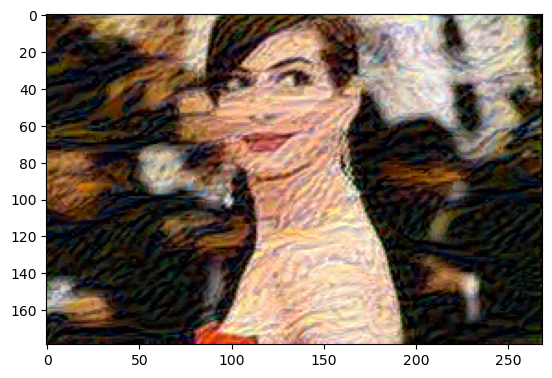

In [11]:
optimizer = optim.Adam(params=[img_create], lr=0.01)
best_img = img_create.clone()

for _e in range(epochs):
    outputs_img_create = model(img_create)

    loss_content = get_content_loss(outputs_img_create[-1], outputs_img[-1])
    loss_style = get_style_loss(outputs_img_create, gram_matrix_style)
    loss = content_weight * loss_content + style_weight * loss_style

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    img_create.data.clamp_(0, 1)

    if loss < best_loss or best_loss < 0:
      best_loss = loss
      best_img = img_create.clone()

    print(f'Iteration: {_e}, loss: {loss.item(): .4f}')

x = best_img.detach().squeeze()
low, hi = torch.amin(x), torch.amax(x)
x = (x - low) / (hi - low) * 255.0
x = x.permute(1, 2, 0)
x = x.numpy()
x = np.clip(x, 0, 255).astype('uint8')

image = Image.fromarray(x, 'RGB')
image.save("result.jpg")

print(best_loss)
plt.imshow(x)
plt.show()